In [2]:
# Species: setosa, versicolor, or virginica

%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import mglearn

# Import dataset
from sklearn.datasets import load_iris
iris_dataset = load_iris()

# Show data categories (keys) within the dataset
# data: actual measurements - becomes X
# target: actual species labels - becomes y
# feature_names: strings of each measurement
# target_names: strings of each species
# DESCR: text description of dataset
# filename: where the raw file lives on disk
print("Keys of iris_dataset: \n{}".format(iris_dataset.keys()))

Keys of iris_dataset: 
dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])


In [3]:
# Split data into training and testing sets
from sklearn.model_selection import train_test_split
# Split into 4 pieces
# iris_dataset['data']: the features/measurements become X
# iris_dataset['target']: the labels/species become y
# random_state=0: makes this split repeatable - always poroduce the same split
X_train, X_test, y_train, y_test = train_test_split(
 iris_dataset['data'], iris_dataset['target'], random_state=0)

print("X_train shape: {}".format(X_train.shape))
print("y_train shape: {}".format(y_train.shape))

print("X_test shape: {}".format(X_test.shape))
print("y_test shape: {}".format(y_test.shape))

X_train shape: (112, 4)
y_train shape: (112,)
X_test shape: (38, 4)
y_test shape: (38,)


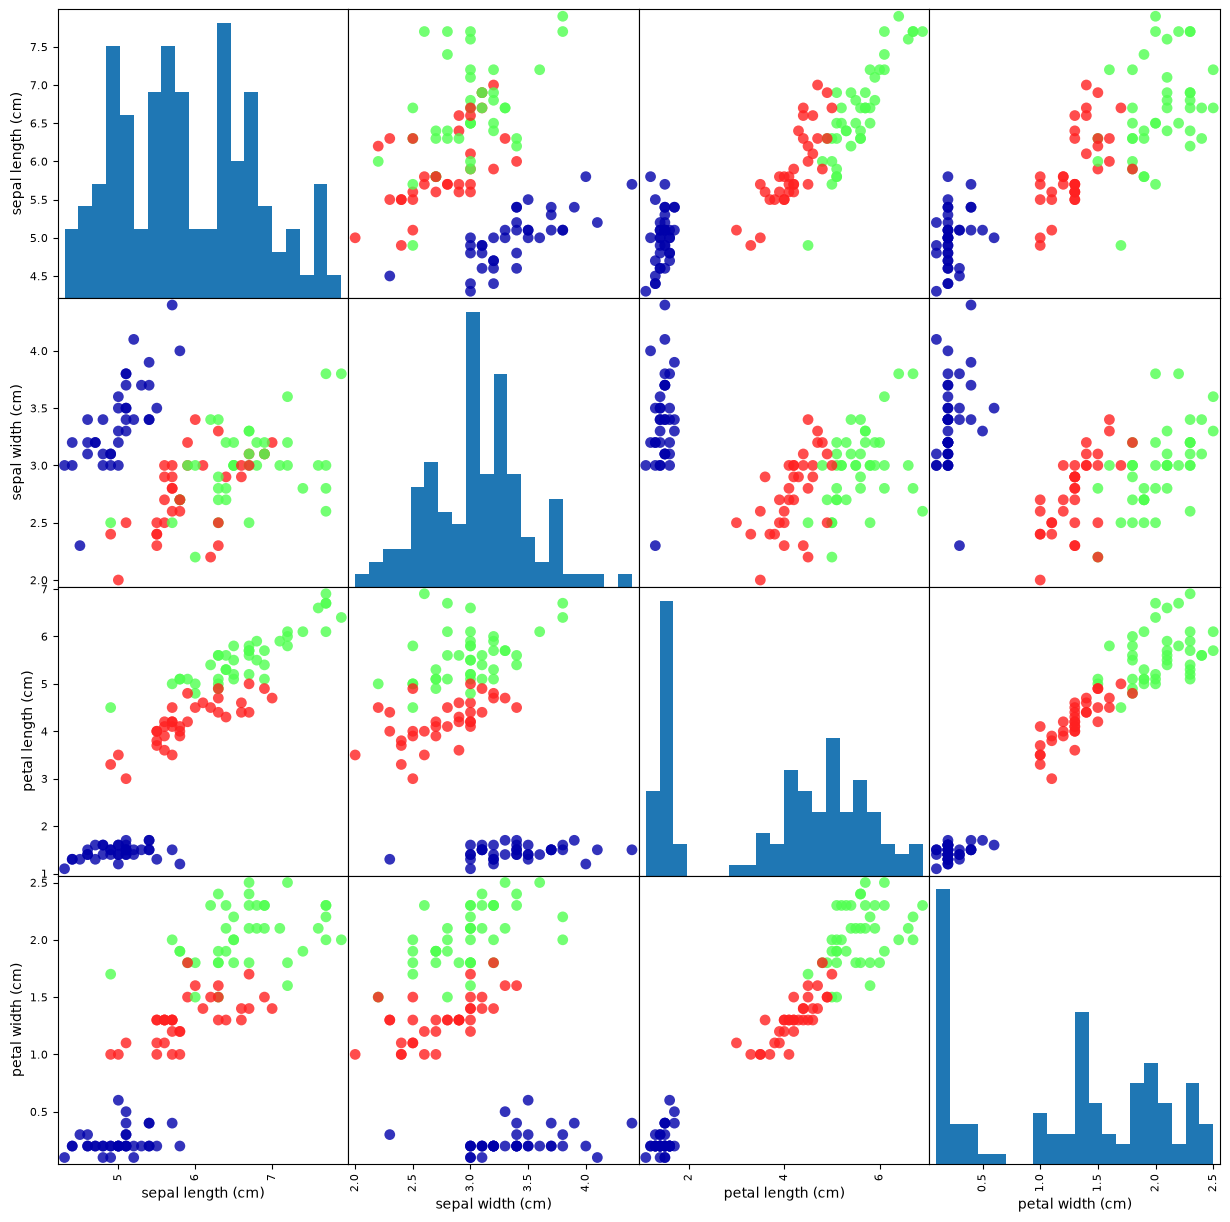

In [9]:
# Create pandas Dataframe (table) out of training data (X_train)
# columns=iris_dataset.feature_names tells pandas what to name the columns
iris_dataframe = pd.DataFrame(X_train, columns=iris_dataset.feature_names)

# Create a scatter matrix: grid of scatter plots comparing every pair of features to spot patterns
grr = pd.plotting.scatter_matrix(
    iris_dataframe, # the table of features to plot
    c=y_train, # colour each point by its species label
    figsize=(15, 15), # size of overall figure
    marker='o', # use circles to represent each point
 hist_kwds={'bins': 20}, # diagonal plots are histograms
    s=60, # size of each plotted dot
    alpha=.8, # transparency of points
    
    cmap=mglearn.cm3 # colour map 
)

In [5]:
from sklearn.neighbors import KNeighborsClassifier
# Create knn model to look at the first closest neighbour
knn = KNeighborsClassifier(n_neighbors=1)

# 'Train' model - just stores X_train and y_train
knn.fit(X_train, y_train)

# Create new sample to test the model
X_new = np.array([[5, 2.9, 1, 0.2]])
print("X_new.shape: {}".format(X_new.shape))

X_new.shape: (1, 4)


In [6]:
# Predict new sample - find closest neighbour in X_train
prediction = knn.predict(X_new)
print("Prediction: {}".format(prediction))
print("Predicted target name: {}".format(
 iris_dataset['target_names'][prediction]))

Prediction: [0]
Predicted target name: ['setosa']


In [7]:
# Predict for all samples in the test set
y_pred = knn.predict(X_test)

# Print every prediction made
print("Test set predictions:\n {}".format(y_pred))

# .score() compared y_pred (model's predictions) against y_test (answers) - 97% accuracy in this case
print("Test set score: {:.2f}".format(knn.score(X_test, y_test)))

Test set predictions:
 [2 1 0 2 0 2 0 1 1 1 2 1 1 1 1 0 1 1 0 0 2 1 0 0 2 0 0 1 1 0 2 1 0 2 2 1 0
 2]
Test set score: 0.97


In [ ]:
# Summary of code needed to work
# X_train, X_test, y_train, y_test = train_test_split(
#  iris_dataset['data'], iris_dataset['target'], random_state=0)
# knn = KNeighborsClassifier(n_neighbors=1)
# knn.fit(X_train, y_train)
# print("Test set score: {:.2f}".format(knn.score(X_test, y_test)))
